# Phase 0-C: nuPlan vs WOMD Side-by-Side Comparison

This notebook loads **one nuPlan npz** and **one WOMD scenario protobuf**, places them side-by-side,
and performs element-by-element verification of the mapping logic before proceeding to Phase 1.

## Checklist

Each section ends with a **PASS/FAIL** verdict. All must pass before entering Phase 1.

1. Ego trajectory format (coordinate system, heading representation)
2. Neighbor agent selection logic (distance sorting, type distribution)
3. Lane 12-dim feature composition (center + direction + boundary offset + TL)
4. Route lanes synthesis feasibility
5. Static objects handling
6. History padding strategy
7. Speed limit unit conversion

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from collections import defaultdict
import os
import sys

import tensorflow as tf

# Import Waymo proto definitions (auto-compile if pip package unavailable)
try:
    from waymo_open_dataset.protos import scenario_pb2
    from waymo_open_dataset.protos import map_pb2
except ImportError:
    _out_dir = os.path.join(os.path.dirname(os.path.abspath("__file__")), "_womd_protos")
    _pb2_flag = os.path.join(_out_dir, "waymo_open_dataset", "protos", "scenario_pb2.py")
    if not os.path.exists(_pb2_flag):
        print("Compiling Waymo proto definitions (one-time setup)...")
        import urllib.request, pathlib, re
        from grpc_tools import protoc as _protoc

        _src = os.path.join(_out_dir, "_src")
        _proto_pkg = os.path.join(_src, "waymo_open_dataset", "protos")
        pathlib.Path(_proto_pkg).mkdir(parents=True, exist_ok=True)

        _base = "https://raw.githubusercontent.com/waymo-research/waymo-open-dataset/master/src/waymo_open_dataset/protos"
        urllib.request.urlretrieve(f"{_base}/map.proto", os.path.join(_proto_pkg, "map.proto"))
        urllib.request.urlretrieve(f"{_base}/scenario.proto", os.path.join(_proto_pkg, "scenario.proto"))

        # Patch scenario.proto: remove camera/lidar imports & fields (not needed for motion data)
        _sp = os.path.join(_proto_pkg, "scenario.proto")
        _txt = open(_sp).read()
        _txt = re.sub(r'import "waymo_open_dataset/protos/camera_tokens\.proto";\n', '', _txt)
        _txt = re.sub(r'import "waymo_open_dataset/protos/compressed_lidar\.proto";\n', '', _txt)
        _txt = re.sub(r'^\s*repeated CompressedFrameLaserData.*?\n', '', _txt, flags=re.MULTILINE)
        _txt = re.sub(r'^\s*repeated FrameCameraTokens.*?\n', '', _txt, flags=re.MULTILINE)
        _txt = re.sub(r'^\s*// Per time step Lidar data\..*?\n', '', _txt, flags=re.MULTILINE)
        _txt = re.sub(r'^\s*// This field is not populated.*?\n', '', _txt, flags=re.MULTILINE)
        _txt = re.sub(r'^\s*// Per time step camera tokens\..*?\n', '', _txt, flags=re.MULTILINE)
        open(_sp, 'w').write(_txt)

        pathlib.Path(os.path.join(_out_dir, "waymo_open_dataset", "protos")).mkdir(parents=True, exist_ok=True)
        pathlib.Path(os.path.join(_out_dir, "waymo_open_dataset", "__init__.py")).touch()
        pathlib.Path(os.path.join(_out_dir, "waymo_open_dataset", "protos", "__init__.py")).touch()

        _protoc.main(["grpc_tools.protoc", f"--proto_path={_src}", f"--python_out={_out_dir}",
                       os.path.join(_proto_pkg, "map.proto"),
                       os.path.join(_proto_pkg, "scenario.proto")])
        print("Done.")

    sys.path.insert(0, _out_dir)
    from waymo_open_dataset.protos import scenario_pb2
    from waymo_open_dataset.protos import map_pb2

%matplotlib inline
plt.rcParams['figure.dpi'] = 120

In [4]:
# ============================================================
# >>> USER CONFIG
# ============================================================
NPZ_PATH = "/Users/eddiesyn/code/GRID-Planner/samples/sg-one-north_0597666a31f55707.npz"            # Path to a nuPlan .npz file
TFRECORD_PATH = "/Users/eddiesyn/code/GRID-Planner/samples/training.tfrecord-00459-of-01000"       # Path to a WOMD TFRecord file
SCENARIO_INDEX = 0       # Which scenario in the TFRecord

# Load nuPlan data
assert os.path.exists(NPZ_PATH), f"NPZ not found: {NPZ_PATH}"
npz = np.load(NPZ_PATH, allow_pickle=True)
print("nuPlan NPZ keys:", sorted(npz.keys()))

# Load WOMD data
assert os.path.exists(TFRECORD_PATH), f"TFRecord not found: {TFRECORD_PATH}"
dataset = tf.data.TFRecordDataset(TFRECORD_PATH)
scenario = None
for idx, raw_record in enumerate(dataset):
    if idx == SCENARIO_INDEX:
        scenario = scenario_pb2.Scenario()
        scenario.ParseFromString(raw_record.numpy())
        break
assert scenario is not None
print(f"WOMD Scenario: {scenario.scenario_id}, {len(scenario.tracks)} tracks, {len(scenario.map_features)} map features")

nuPlan NPZ keys: ['crosswalks', 'ego_agent_future', 'ego_agent_past', 'ego_current_state', 'lanes', 'lanes_has_speed_limit', 'lanes_speed_limit', 'map_name', 'neighbor_agents_future', 'neighbor_agents_past', 'route_lanes', 'route_lanes_has_speed_limit', 'route_lanes_speed_limit', 'route_polygons', 'static_objects', 'token']
WOMD Scenario: f4fe5a9237be3d73, 57 tracks, 408 map features


2026-02-12 16:31:17.545004: I tensorflow/core/kernels/data/tf_record_dataset_op.cc:390] TFRecordDataset `buffer_size` is unspecified, default to 262144


In [5]:
# ============================================================
# Common helpers
# ============================================================

# WOMD helpers
ct = scenario.current_time_index
sdc = scenario.tracks[scenario.sdc_track_index]
sdc_states = sdc.states
sdc_x_global = np.array([s.center_x for s in sdc_states])
sdc_y_global = np.array([s.center_y for s in sdc_states])
sdc_h_global = np.array([s.heading for s in sdc_states])
sdc_vx = np.array([s.velocity_x for s in sdc_states])
sdc_vy = np.array([s.velocity_y for s in sdc_states])
sdc_valid = np.array([s.valid for s in sdc_states])
sdc_w = np.array([s.width for s in sdc_states])
sdc_l = np.array([s.length for s in sdc_states])

# Ego-centric transform for WOMD
ego_x0, ego_y0, ego_h0 = sdc_x_global[ct], sdc_y_global[ct], sdc_h_global[ct]
cos_neg_h, sin_neg_h = np.cos(-ego_h0), np.sin(-ego_h0)

def womd_to_ego(x, y):
    """Transform WOMD global coords to ego-centric frame."""
    dx = x - ego_x0
    dy = y - ego_y0
    return dx * cos_neg_h - dy * sin_neg_h, dx * sin_neg_h + dy * cos_neg_h

def womd_heading_to_ego(h):
    """Transform WOMD global heading to ego-centric."""
    return h - ego_h0

# Map features
map_by_id = {}
womd_lanes = []
for mf in scenario.map_features:
    map_by_id[mf.id] = mf
    if mf.HasField('lane'):
        womd_lanes.append(mf)

# nuPlan data
np_ego_past = npz['ego_agent_past']          # (21, 14)
np_ego_current = npz['ego_current_state']     # (16,)
np_ego_future = npz['ego_agent_future']       # (80, 3)
np_nb_past = npz['neighbor_agents_past']      # (32, 21, 11)
np_nb_future = npz['neighbor_agents_future']  # (32, 80, 3)
np_lanes = npz['lanes']                       # (70, 20, 12)
np_route = npz['route_lanes']                 # (25, 20, 12)
np_static = npz['static_objects']             # (5, 10)
np_speed = npz['lanes_speed_limit']           # (70, 1)
np_has_speed = npz['lanes_has_speed_limit']   # (70, 1)

print("Data loaded successfully.")

Data loaded successfully.


---
## 1. Ego Trajectory: Coordinate System & Heading

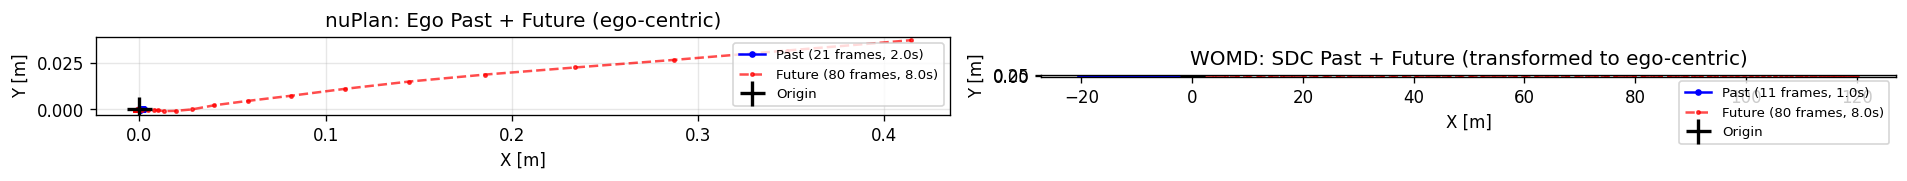


EGO TRAJECTORY COMPARISON
                                        nuPlan            WOMD
Past frames                                 21              11
Future frames                               80              80
Current pos near origin                    Yes             Yes
Heading repr                           cos/sin         radians
Ego dims                       14d past, 16d cur      raw states

ACTION ITEMS:
  - Convert WOMD heading to cos/sin
  - Pad WOMD past from 11 to 21 frames
  - Compute acceleration from velocity finite differences
  - Compute steering_angle and yaw_rate from heading differences


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ---- nuPlan ----
ax = axes[0]
ax.set_aspect('equal')
ax.set_title('nuPlan: Ego Past + Future (ego-centric)')
ax.plot(np_ego_past[:, 0], np_ego_past[:, 1], 'b-o', markersize=3, linewidth=1.5, label='Past (21 frames, 2.0s)')
ax.plot(np_ego_future[:, 0], np_ego_future[:, 1], 'r--o', markersize=2, linewidth=1.5, label='Future (80 frames, 8.0s)', alpha=0.7)
ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2, label='Origin')
ax.set_xlabel('X [m]'); ax.set_ylabel('Y [m]')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ---- WOMD ----
ax = axes[1]
ax.set_aspect('equal')
ax.set_title('WOMD: SDC Past + Future (transformed to ego-centric)')

sdc_lx, sdc_ly = womd_to_ego(sdc_x_global, sdc_y_global)
past_v = sdc_valid[:ct+1]
fut_v = sdc_valid[ct+1:]

ax.plot(sdc_lx[:ct+1][past_v], sdc_ly[:ct+1][past_v], 'b-o', markersize=3, linewidth=1.5,
        label=f'Past ({past_v.sum()} frames, {ct*0.1:.1f}s)')
ax.plot(sdc_lx[ct+1:][fut_v], sdc_ly[ct+1:][fut_v], 'r--o', markersize=2, linewidth=1.5,
        label=f'Future ({fut_v.sum()} frames, {(len(sdc_states)-ct-1)*0.1:.1f}s)', alpha=0.7)
ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2, label='Origin')
ax.set_xlabel('X [m]'); ax.set_ylabel('Y [m]')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Statistics comparison
print("\n" + "="*60)
print("EGO TRAJECTORY COMPARISON")
print("="*60)
print(f"{'':30s} {'nuPlan':>15s} {'WOMD':>15s}")
print(f"{'Past frames':30s} {np_ego_past.shape[0]:>15d} {int(past_v.sum()):>15d}")
print(f"{'Future frames':30s} {np_ego_future.shape[0]:>15d} {int(fut_v.sum()):>15d}")
print(f"{'Current pos near origin':30s} {'Yes' if np.sqrt(np_ego_current[0]**2+np_ego_current[1]**2)<1 else 'No':>15s} {'Yes' if abs(sdc_lx[ct])<0.01 and abs(sdc_ly[ct])<0.01 else 'No':>15s}")
print(f"{'Heading repr':30s} {'cos/sin':>15s} {'radians':>15s}")
print(f"{'Ego dims':30s} {f'{np_ego_past.shape[1]}d past, {np_ego_current.shape[0]}d cur':>15s} {'raw states':>15s}")
print(f"\nACTION ITEMS:")
print(f"  - Convert WOMD heading to cos/sin")
print(f"  - Pad WOMD past from {int(past_v.sum())} to 21 frames")
print(f"  - Compute acceleration from velocity finite differences")
print(f"  - Compute steering_angle and yaw_rate from heading differences")

---
## 2. Neighbor Agents: Selection & Type Distribution

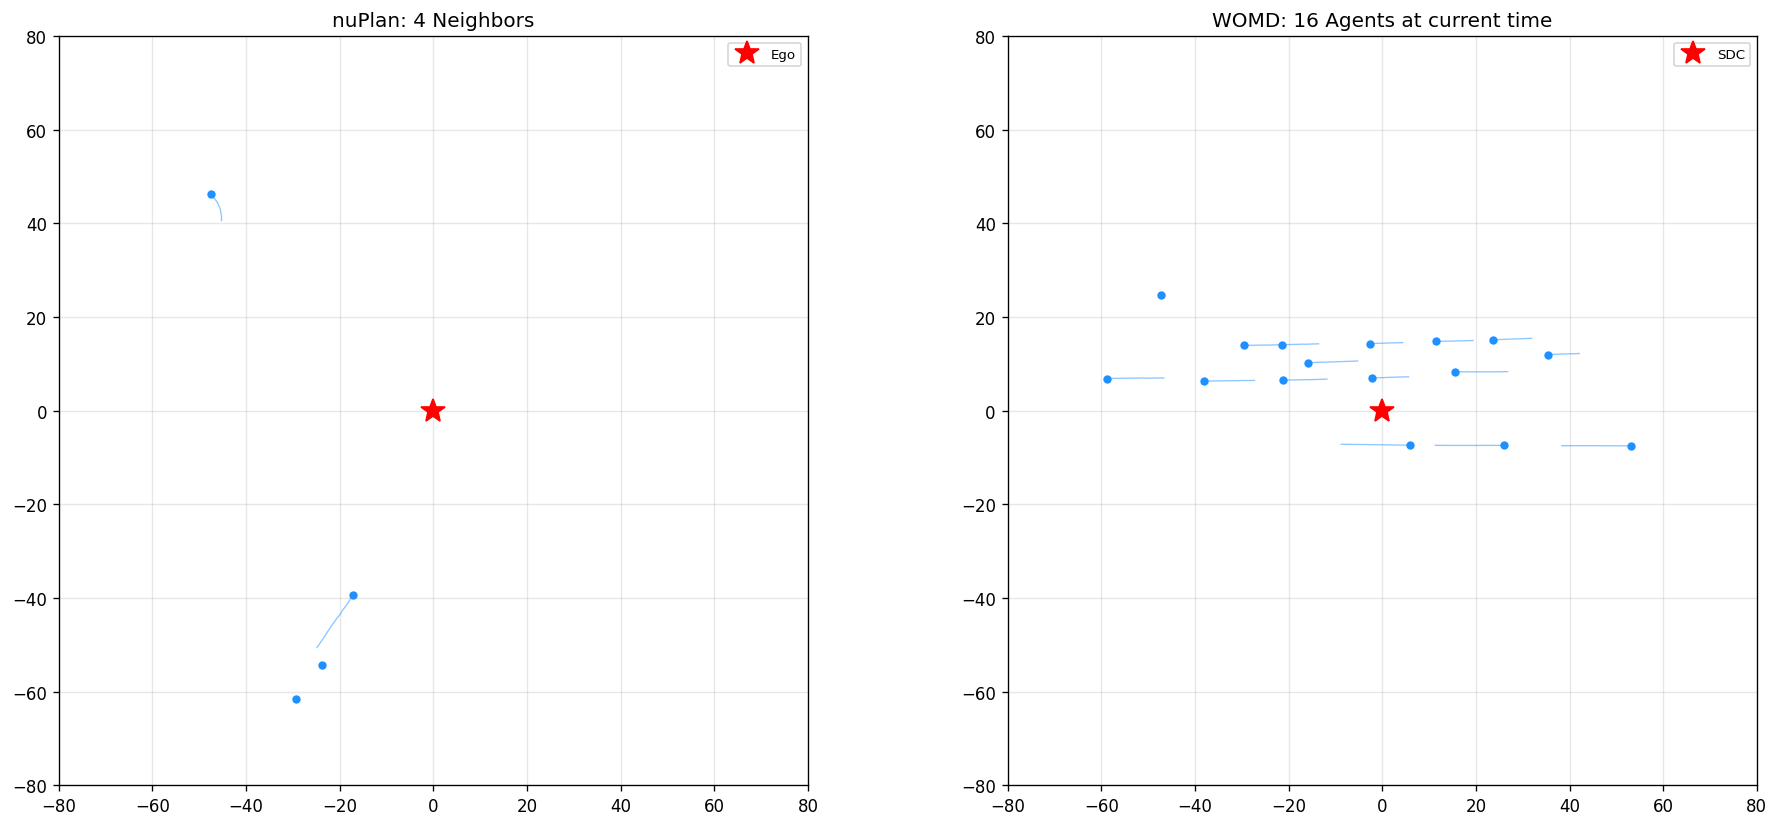


NEIGHBOR AGENT COMPARISON
                                        nuPlan            WOMD
Max slots                                   32     32 (target)
Real agents                                  4              16
Vehicles                                     4              16
Pedestrians                                  0               0
Bicycles/Cyclists                            0               0
Others (WOMD only)                         N/A               0
Past features dim                           11         need 11
Future features dim                          3          need 3

ACTION ITEMS:
  - Select 32 nearest agents at current time (max 10 ped+cyclist)
  - Map CYCLIST -> BICYCLE, ignore OTHER
  - Agent past: [x, y, cos_h, sin_h, vx, vy, width, length, type_onehot(3)]
  - Agent future: [x, y, heading] in ego-centric
  - Pad agent past from 11 to 21 frames


In [7]:
# nuPlan neighbor stats
np_n_real = 0
np_type_counts = {'vehicle': 0, 'pedestrian': 0, 'bicycle': 0}
for i in range(np_nb_past.shape[0]):
    if np.any(np.abs(np_nb_past[i, -1]) > 1e-6):
        np_n_real += 1
        t = np_nb_past[i, -1, 8:11]
        if t[0] > 0.5: np_type_counts['vehicle'] += 1
        elif t[1] > 0.5: np_type_counts['pedestrian'] += 1
        elif t[2] > 0.5: np_type_counts['bicycle'] += 1

# WOMD neighbor stats (valid at current time, within 80m)
OBJ_TYPE = {1: 'vehicle', 2: 'pedestrian', 3: 'bicycle', 4: 'other'}
womd_agents = []
womd_type_counts = {'vehicle': 0, 'pedestrian': 0, 'bicycle': 0, 'other': 0}
for i, track in enumerate(scenario.tracks):
    if i == scenario.sdc_track_index:
        continue
    if not track.states[ct].valid:
        continue
    s = track.states[ct]
    lx, ly = womd_to_ego(np.array([s.center_x]), np.array([s.center_y]))
    dist = np.sqrt(lx[0]**2 + ly[0]**2)
    obj_type = OBJ_TYPE.get(track.object_type, 'other')
    womd_type_counts[obj_type] += 1
    womd_agents.append((i, dist, obj_type))

# Sort by distance
womd_agents.sort(key=lambda x: x[1])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

NP_COLORS = {'vehicle': 'dodgerblue', 'pedestrian': 'orange', 'bicycle': 'limegreen'}

# nuPlan
ax = axes[0]
ax.set_aspect('equal')
ax.set_title(f'nuPlan: {np_n_real} Neighbors')
for i in range(np_nb_past.shape[0]):
    if not np.any(np.abs(np_nb_past[i, -1]) > 1e-6): continue
    t = np_nb_past[i, -1, 8:11]
    if t[0] > 0.5: c = 'dodgerblue'
    elif t[1] > 0.5: c = 'orange'
    else: c = 'limegreen'
    ax.plot(np_nb_past[i, :, 0], np_nb_past[i, :, 1], '-', color=c, linewidth=0.8, alpha=0.5)
    ax.plot(np_nb_past[i, -1, 0], np_nb_past[i, -1, 1], 'o', color=c, markersize=4)
ax.plot(0, 0, 'r*', markersize=15, label='Ego')
ax.set_xlim(-80, 80); ax.set_ylim(-80, 80)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

# WOMD
ax = axes[1]
ax.set_aspect('equal')
ax.set_title(f'WOMD: {len(womd_agents)} Agents at current time')
for track_idx, dist, obj_type in womd_agents:
    if dist > 80: continue
    c = NP_COLORS.get(obj_type, 'gray')
    track = scenario.tracks[track_idx]
    xs = np.array([s.center_x for s in track.states])
    ys = np.array([s.center_y for s in track.states])
    valids = np.array([s.valid for s in track.states])
    lxs, lys = womd_to_ego(xs, ys)
    pv = valids[:ct+1]
    ax.plot(lxs[:ct+1][pv], lys[:ct+1][pv], '-', color=c, linewidth=0.8, alpha=0.5)
    ax.plot(lxs[ct], lys[ct], 'o', color=c, markersize=4)
ax.plot(0, 0, 'r*', markersize=15, label='SDC')
ax.set_xlim(-80, 80); ax.set_ylim(-80, 80)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("NEIGHBOR AGENT COMPARISON")
print("="*60)
print(f"{'':30s} {'nuPlan':>15s} {'WOMD':>15s}")
print(f"{'Max slots':30s} {np_nb_past.shape[0]:>15d} {'32 (target)':>15s}")
print(f"{'Real agents':30s} {np_n_real:>15d} {len(womd_agents):>15d}")
print(f"{'Vehicles':30s} {np_type_counts['vehicle']:>15d} {womd_type_counts['vehicle']:>15d}")
print(f"{'Pedestrians':30s} {np_type_counts['pedestrian']:>15d} {womd_type_counts['pedestrian']:>15d}")
print(f"{'Bicycles/Cyclists':30s} {np_type_counts['bicycle']:>15d} {womd_type_counts['bicycle']:>15d}")
print(f"{'Others (WOMD only)':30s} {'N/A':>15s} {womd_type_counts['other']:>15d}")
print(f"{'Past features dim':30s} {np_nb_past.shape[2]:>15d} {'need 11':>15s}")
print(f"{'Future features dim':30s} {np_nb_future.shape[2]:>15d} {'need 3':>15s}")
print(f"\nACTION ITEMS:")
print(f"  - Select 32 nearest agents at current time (max 10 ped+cyclist)")
print(f"  - Map CYCLIST -> BICYCLE, ignore OTHER")
print(f"  - Agent past: [x, y, cos_h, sin_h, vx, vy, width, length, type_onehot(3)]")
print(f"  - Agent future: [x, y, heading] in ego-centric")
print(f"  - Pad agent past from 11 to 21 frames")

---
## 3. Lane Feature Composition (12-dim)

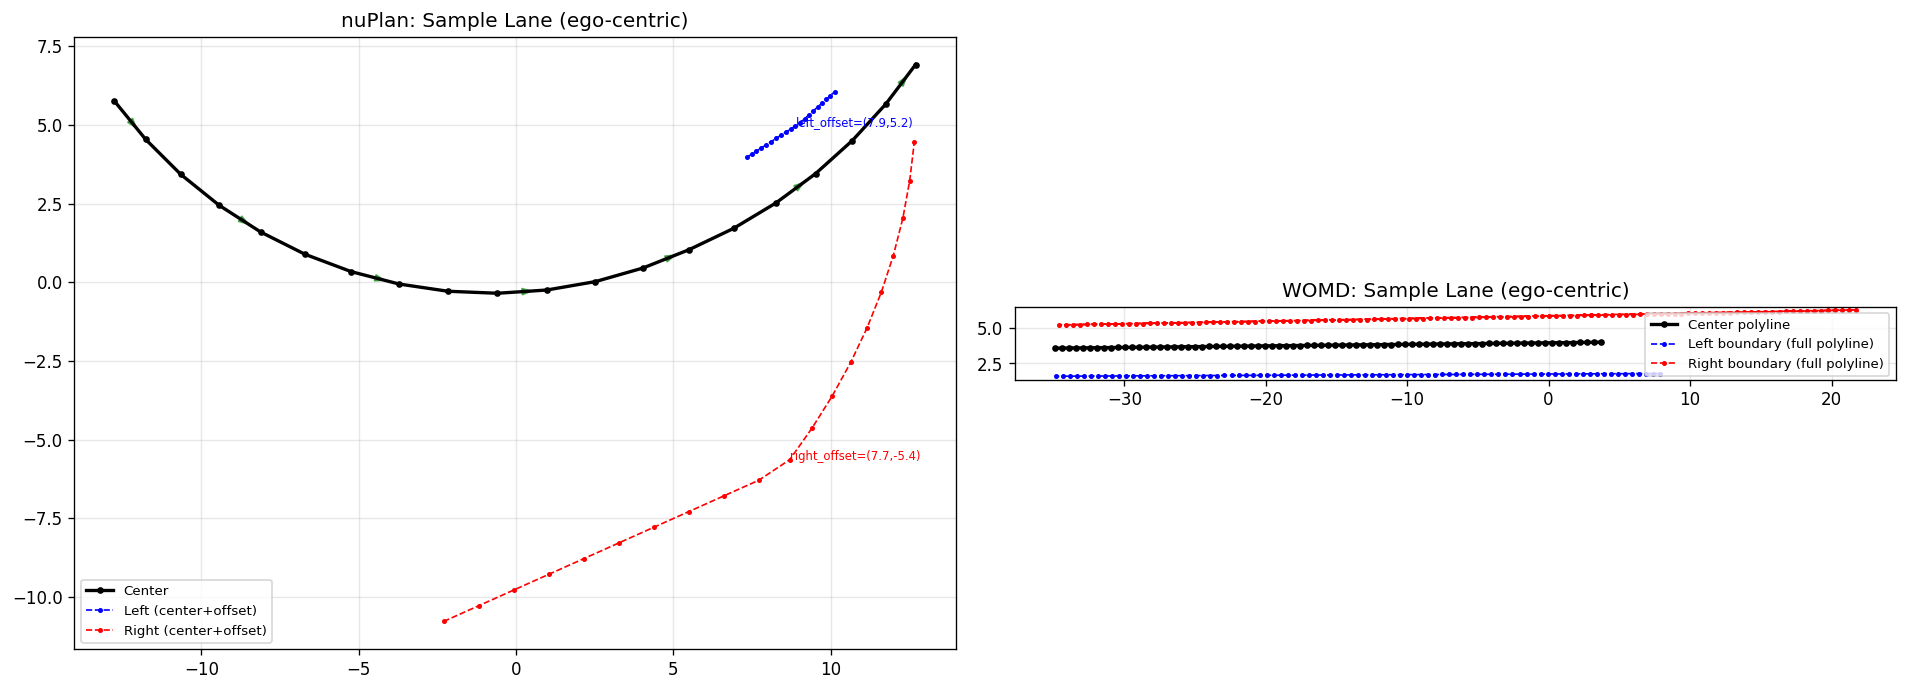


WOMD lane 514: center=79 pts, left_boundary=87 pts, right_boundary=116 pts
NOTE: boundary polyline is the FULL RoadLine/RoadEdge polyline.
  For conversion, need to interpolate center & boundary to same point count,
  then compute offset = boundary_point - center_point.

LANE FEATURE COMPARISON (12 dimensions)
 Dim  nuPlan                          WOMD (to construct)           
 0-1  center_x, center_y              lane.polyline[i].x/y          
 2-3  dx, dy (forward diff)           point[i+1] - point[i]         
 4-5  left_offset_x, left_offset_y    left_boundary - center        
 6-7  right_offset_x, right_offset_y  right_boundary - center       
8-11 tl_green, tl_yellow, tl_red, tl_unk  mapped from lane_states       

KEY OBSERVATIONS:
  - nuPlan boundary dims are OFFSETS from center, not absolute coords
  - WOMD boundaries need interpolation to match center point count
  - Direction vectors in nuPlan: point[j+1] - point[j], last one is zero


In [8]:
def get_polyline(feature_field):
    return np.array([[p.x, p.y] for p in feature_field.polyline])

def resolve_boundary(boundaries, map_by_id):
    """Resolve boundary segments into a single polyline."""
    all_pts = []
    for seg in boundaries:
        feat = map_by_id.get(seg.boundary_feature_id)
        if feat is None: continue
        if feat.HasField('road_line'):
            poly = feat.road_line.polyline
        elif feat.HasField('road_edge'):
            poly = feat.road_edge.polyline
        else:
            continue
        # lane_start_index/lane_end_index are indices into the LANE polyline,
        # not the boundary polyline. Take the full boundary polyline.
        pts = np.array([[p.x, p.y] for p in poly])
        if len(pts) > 0:
            all_pts.append(pts)
    return np.concatenate(all_pts, axis=0) if all_pts else None


# Visualize a sample WOMD lane decomposed into 12-dim features
# Find a lane near the SDC
sdc_pos = np.array([sdc_x_global[ct], sdc_y_global[ct]])
sample_lane = None
for mf in womd_lanes:
    pts = get_polyline(mf.lane)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) < 30 and len(mf.lane.left_boundaries) > 0:
        sample_lane = mf
        break

if sample_lane is not None:
    center = get_polyline(sample_lane.lane)
    left_bnd = resolve_boundary(sample_lane.lane.left_boundaries, map_by_id)
    right_bnd = resolve_boundary(sample_lane.lane.right_boundaries, map_by_id)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # nuPlan sample lane (ego-centric)
    ax = axes[0]
    ax.set_aspect('equal')
    ax.set_title('nuPlan: Sample Lane (ego-centric)')
    # Find a non-zero lane
    for li in range(np_lanes.shape[0]):
        if np.any(np.abs(np_lanes[li]) > 1e-6):
            lane = np_lanes[li]
            cx, cy = lane[:, 0], lane[:, 1]
            lx = cx + lane[:, 4]; ly = cy + lane[:, 5]
            rx = cx + lane[:, 6]; ry = cy + lane[:, 7]
            ax.plot(cx, cy, 'k-o', markersize=3, linewidth=2, label='Center')
            ax.plot(lx, ly, 'b--o', markersize=2, linewidth=1, label='Left (center+offset)')
            ax.plot(rx, ry, 'r--o', markersize=2, linewidth=1, label='Right (center+offset)')
            # Direction vectors
            for j in range(0, lane.shape[0], 3):
                ax.arrow(cx[j], cy[j], lane[j,2]*0.5, lane[j,3]*0.5,
                         head_width=0.2, fc='green', ec='green', alpha=0.6)
            # Annotate offsets
            mid = lane.shape[0] // 2
            ax.annotate(f'left_offset=({lane[mid,4]:.1f},{lane[mid,5]:.1f})',
                        xy=(lx[mid], ly[mid]), fontsize=7, color='blue')
            ax.annotate(f'right_offset=({lane[mid,6]:.1f},{lane[mid,7]:.1f})',
                        xy=(rx[mid], ry[mid]), fontsize=7, color='red')
            break
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    
    # WOMD sample lane (also in ego-centric for fair comparison)
    ax = axes[1]
    ax.set_aspect('equal')
    ax.set_title('WOMD: Sample Lane (ego-centric)')
    c_lx, c_ly = womd_to_ego(center[:, 0], center[:, 1])
    ax.plot(c_lx, c_ly, 'k-o', markersize=3, linewidth=2, label='Center polyline')
    if left_bnd is not None:
        bl_lx, bl_ly = womd_to_ego(left_bnd[:, 0], left_bnd[:, 1])
        ax.plot(bl_lx, bl_ly, 'b--o', markersize=2, linewidth=1, label='Left boundary (full polyline)')
    if right_bnd is not None:
        br_lx, br_ly = womd_to_ego(right_bnd[:, 0], right_bnd[:, 1])
        ax.plot(br_lx, br_ly, 'r--o', markersize=2, linewidth=1, label='Right boundary (full polyline)')
    # Direction vectors
    for j in range(0, len(c_lx)-1, max(1, len(c_lx)//5)):
        ddx = c_lx[j+1] - c_lx[j]
        ddy = c_ly[j+1] - c_ly[j]
        ax.arrow(c_lx[j], c_ly[j], ddx*0.5, ddy*0.5,
                 head_width=0.2, fc='green', ec='green', alpha=0.6)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print point counts for awareness
    print(f"\nWOMD lane {sample_lane.id}: center={len(center)} pts, "
          f"left_boundary={len(left_bnd) if left_bnd is not None else 0} pts, "
          f"right_boundary={len(right_bnd) if right_bnd is not None else 0} pts")
    print(f"NOTE: boundary polyline is the FULL RoadLine/RoadEdge polyline.")
    print(f"  For conversion, need to interpolate center & boundary to same point count,")
    print(f"  then compute offset = boundary_point - center_point.")
else:
    print("No suitable WOMD lane found near SDC for comparison")

print("\n" + "="*60)
print("LANE FEATURE COMPARISON (12 dimensions)")
print("="*60)
print(f"{'Dim':>4s}  {'nuPlan':30s}  {'WOMD (to construct)':30s}")
print(f"{'0-1':>4s}  {'center_x, center_y':30s}  {'lane.polyline[i].x/y':30s}")
print(f"{'2-3':>4s}  {'dx, dy (forward diff)':30s}  {'point[i+1] - point[i]':30s}")
print(f"{'4-5':>4s}  {'left_offset_x, left_offset_y':30s}  {'left_boundary - center':30s}")
print(f"{'6-7':>4s}  {'right_offset_x, right_offset_y':30s}  {'right_boundary - center':30s}")
print(f"{'8-11':>4s} {'tl_green, tl_yellow, tl_red, tl_unk':30s}  {'mapped from lane_states':30s}")
print(f"\nKEY OBSERVATIONS:")
print(f"  - nuPlan boundary dims are OFFSETS from center, not absolute coords")
print(f"  - WOMD boundaries need interpolation to match center point count")
print(f"  - Direction vectors in nuPlan: point[j+1] - point[j], last one is zero")

---
## 4. Traffic Light Encoding

In [9]:
# nuPlan TL statistics
np_tl_stats = {'green': 0, 'yellow': 0, 'red': 0, 'unknown': 0, 'none': 0}
for i in range(np_lanes.shape[0]):
    if not np.any(np.abs(np_lanes[i]) > 1e-6): continue
    tl = np_lanes[i, 0, 8:12]
    if tl[0] > 0.5: np_tl_stats['green'] += 1
    elif tl[1] > 0.5: np_tl_stats['yellow'] += 1
    elif tl[2] > 0.5: np_tl_stats['red'] += 1
    elif tl[3] > 0.5: np_tl_stats['unknown'] += 1
    else: np_tl_stats['none'] += 1

# WOMD TL statistics
TL_MAP = {0:'UNKNOWN', 1:'STOP', 2:'CAUTION', 3:'GO', 4:'STOP', 5:'CAUTION', 6:'GO', 7:'STOP', 8:'CAUTION'}
womd_tl_at_ct = {}
if ct < len(scenario.dynamic_map_states):
    for ls in scenario.dynamic_map_states[ct].lane_states:
        womd_tl_at_ct[ls.lane] = TL_MAP.get(ls.state, 'UNKNOWN')

womd_tl_stats = defaultdict(int)
for v in womd_tl_at_ct.values():
    womd_tl_stats[v] += 1

print("="*60)
print("TRAFFIC LIGHT ENCODING COMPARISON")
print("="*60)
print(f"\nnuPlan encoding (one-hot per point): [green, yellow, red, unknown]")
print(f"  green={np_tl_stats['green']}, yellow={np_tl_stats['yellow']}, "
      f"red={np_tl_stats['red']}, unknown={np_tl_stats['unknown']}, none={np_tl_stats['none']}")

print(f"\nWOMD at current time: {len(womd_tl_at_ct)} lanes with TL")
for k, v in sorted(womd_tl_stats.items()):
    print(f"  {k}: {v}")

print(f"\nMapping (WOMD -> nuPlan one-hot):")
print(f"  GO / ARROW_GO               -> [1, 0, 0, 0]  (green)")
print(f"  CAUTION / ARROW_CAUTION / FLASHING_CAUTION -> [0, 1, 0, 0]  (yellow)")
print(f"  STOP / ARROW_STOP / FLASHING_STOP    -> [0, 0, 1, 0]  (red)")
print(f"  UNKNOWN                      -> [0, 0, 0, 1]  (unknown)")
print(f"  No TL for lane               -> [0, 0, 0, 0]  (all zeros)")

TRAFFIC LIGHT ENCODING COMPARISON

nuPlan encoding (one-hot per point): [green, yellow, red, unknown]
  green=0, yellow=0, red=0, unknown=70, none=0

WOMD at current time: 6 lanes with TL
  GO: 4
  UNKNOWN: 2

Mapping (WOMD -> nuPlan one-hot):
  GO / ARROW_GO               -> [1, 0, 0, 0]  (green)
  CAUTION / ARROW_CAUTION / FLASHING_CAUTION -> [0, 1, 0, 0]  (yellow)
  STOP / ARROW_STOP / FLASHING_STOP    -> [0, 0, 1, 0]  (red)
  UNKNOWN                      -> [0, 0, 0, 1]  (unknown)
  No TL for lane               -> [0, 0, 0, 0]  (all zeros)


---
## 5. Route Lanes

ROUTE LANES COMPARISON

nuPlan route_lanes: 6 real lanes (max 25)
  - Shape: (25, 20, 12)
  - Same 12-dim format as regular lanes
  - Extracted from scenario's route_roadblock_ids

WOMD: NO route concept
  - Synthesis plan: Project SDC future trajectory onto nearest lanes
  - Collect ordered unique lane IDs that form the route
  - Convert to same 12-dim format, max 25 lanes


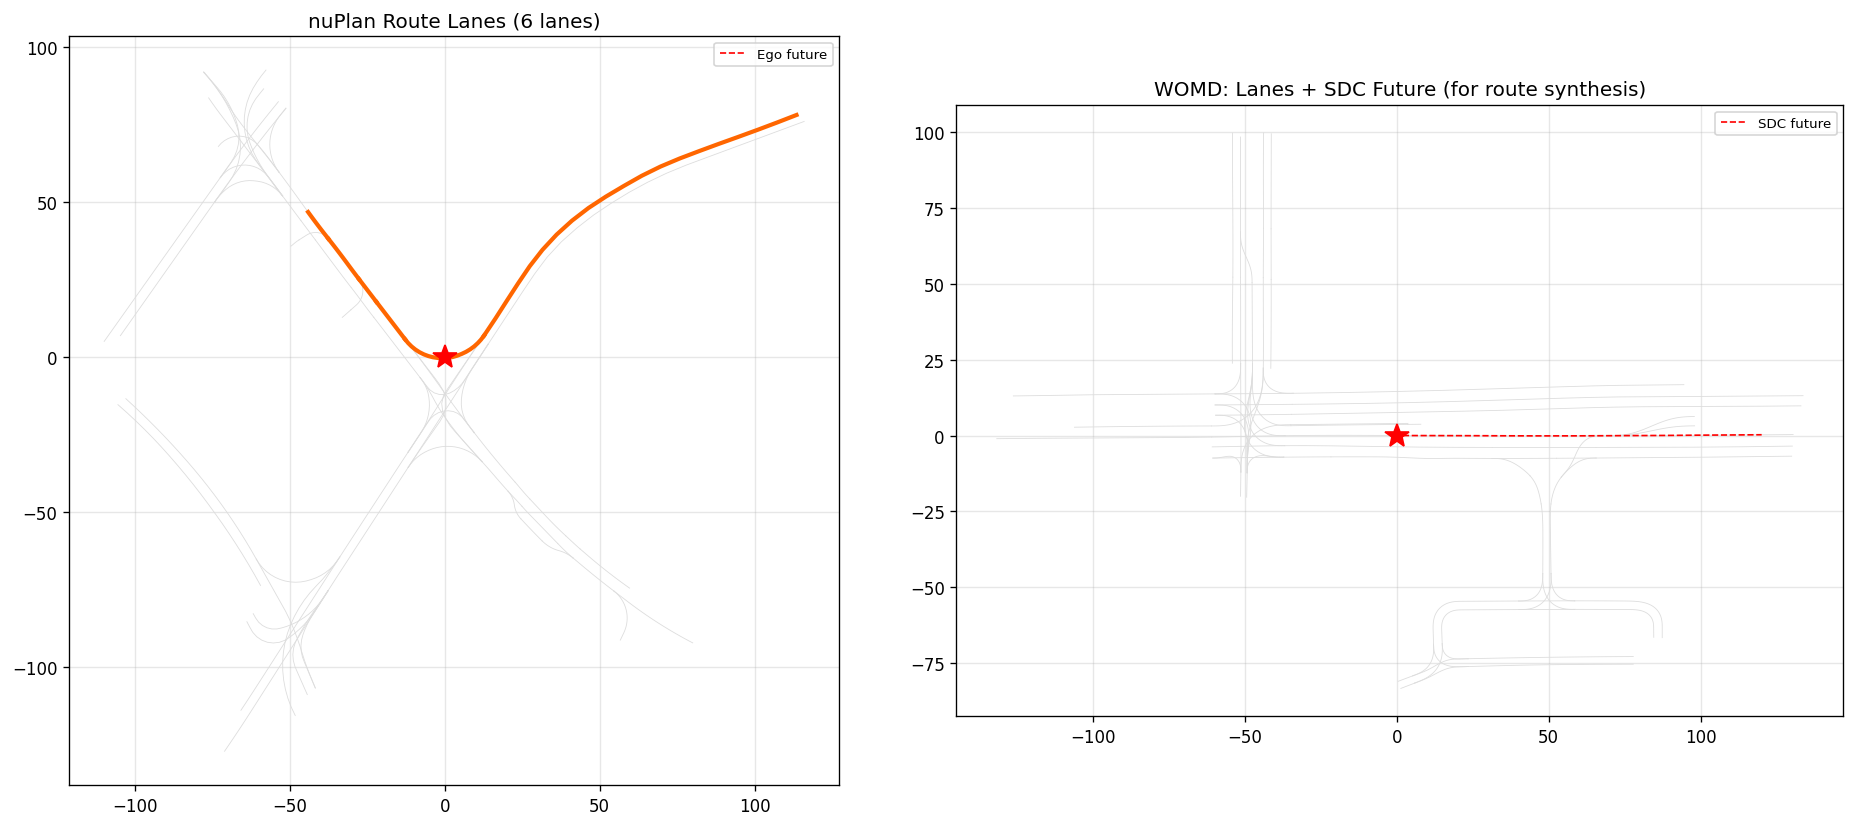

In [10]:
n_np_route = sum(1 for i in range(np_route.shape[0]) if np.any(np.abs(np_route[i]) > 1e-6))

print("="*60)
print("ROUTE LANES COMPARISON")
print("="*60)
print(f"\nnuPlan route_lanes: {n_np_route} real lanes (max {np_route.shape[0]})")
print(f"  - Shape: {np_route.shape}")
print(f"  - Same 12-dim format as regular lanes")
print(f"  - Extracted from scenario's route_roadblock_ids")

print(f"\nWOMD: NO route concept")
print(f"  - Synthesis plan: Project SDC future trajectory onto nearest lanes")
print(f"  - Collect ordered unique lane IDs that form the route")
print(f"  - Convert to same 12-dim format, max 25 lanes")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax = axes[0]
ax.set_aspect('equal')
ax.set_title(f'nuPlan Route Lanes ({n_np_route} lanes)')
for i in range(np_lanes.shape[0]):
    if np.any(np.abs(np_lanes[i]) > 1e-6):
        ax.plot(np_lanes[i,:,0], np_lanes[i,:,1], '-', color='#dddddd', linewidth=0.5)
for i in range(np_route.shape[0]):
    if np.any(np.abs(np_route[i]) > 1e-6):
        ax.plot(np_route[i,:,0], np_route[i,:,1], '-', color='#ff6600', linewidth=2.5)
ax.plot(np_ego_future[:,0], np_ego_future[:,1], 'r--', linewidth=1, label='Ego future')
ax.plot(0, 0, 'r*', markersize=15)
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)

ax = axes[1]
ax.set_aspect('equal')
ax.set_title('WOMD: Lanes + SDC Future (for route synthesis)')
for mf in womd_lanes:
    pts = get_polyline(mf.lane)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) > 100: continue
    lx, ly = womd_to_ego(pts[:,0], pts[:,1])
    ax.plot(lx, ly, '-', color='#dddddd', linewidth=0.5)
fut_v2 = sdc_valid[ct+1:]
flx, fly = womd_to_ego(sdc_x_global[ct+1:][fut_v2], sdc_y_global[ct+1:][fut_v2])
ax.plot(flx, fly, 'r--', linewidth=1, label='SDC future')
ax.plot(0, 0, 'r*', markersize=15)
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## 6. Static Objects

In [11]:
np_n_static = sum(1 for i in range(np_static.shape[0]) if np.any(np.abs(np_static[i]) > 1e-6))
STATIC_TYPES = ['czone_sign', 'barrier', 'traffic_cone', 'generic']
np_static_types = {}
for i in range(np_static.shape[0]):
    if np.any(np.abs(np_static[i]) > 1e-6):
        t = STATIC_TYPES[np.argmax(np_static[i, 6:10])]
        np_static_types[t] = np_static_types.get(t, 0) + 1

# WOMD stop signs near SDC
womd_stop_signs_near = []
for mf in scenario.map_features:
    if mf.HasField('stop_sign'):
        pos = mf.stop_sign.position
        lx, ly = womd_to_ego(np.array([pos.x]), np.array([pos.y]))
        dist = np.sqrt(lx[0]**2 + ly[0]**2)
        if dist < 100:
            womd_stop_signs_near.append((lx[0], ly[0], dist))

print("="*60)
print("STATIC OBJECTS COMPARISON")
print("="*60)
print(f"\nnuPlan static_objects: {np_n_static} objects (max 5)")
print(f"  Shape: {np_static.shape}")
print(f"  Dims: x, y, cos_h, sin_h, width, length, [czone_sign, barrier, cone, generic]")
print(f"  Type distribution: {np_static_types}")

print(f"\nWOMD available static objects:")
womd_stop_count = sum(1 for mf in scenario.map_features if mf.HasField('stop_sign'))
womd_cw_count = sum(1 for mf in scenario.map_features if mf.HasField('crosswalk'))
womd_sb_count = sum(1 for mf in scenario.map_features if mf.HasField('speed_bump'))
print(f"  stop_sign: {womd_stop_count} (near SDC: {len(womd_stop_signs_near)})")
print(f"  crosswalk: {womd_cw_count}")
print(f"  speed_bump: {womd_sb_count}")
print(f"  barrier/cone/czone_sign: NOT available in WOMD")

print(f"\nMAPPING PLAN:")
print(f"  - Use stop_sign positions for static_objects (heading=0, width/length approx)")
print(f"  - Zero-pad remaining slots")
print(f"  - Type one-hot: all zeros or use [0,0,0,1] (generic) for stop signs")
print(f"  - NOTE: This is lossy but acceptable since model was trained on nuPlan")
print(f"          and static objects are a minor feature")

STATIC OBJECTS COMPARISON

nuPlan static_objects: 2 objects (max 5)
  Shape: (5, 10)
  Dims: x, y, cos_h, sin_h, width, length, [czone_sign, barrier, cone, generic]
  Type distribution: {'traffic_cone': 1, 'generic': 1}

WOMD available static objects:
  stop_sign: 0 (near SDC: 0)
  crosswalk: 12
  speed_bump: 8
  barrier/cone/czone_sign: NOT available in WOMD

MAPPING PLAN:
  - Use stop_sign positions for static_objects (heading=0, width/length approx)
  - Zero-pad remaining slots
  - Type one-hot: all zeros or use [0,0,0,1] (generic) for stop signs
  - NOTE: This is lossy but acceptable since model was trained on nuPlan
          and static objects are a minor feature


---
## 7. History Padding Strategy

HISTORY PADDING ANALYSIS

nuPlan past frames: 21 (2.0s at 10Hz, including current)
WOMD past frames: 11 (current_time_index=10, 1.0s including current)
Padding needed: 10 frames

Padding strategy: Repeat the EARLIEST valid state 10 times
  This fills frames [0..9] with the state at WOMD frame 0
  WOMD frames 0..10 map to output frames 10..20
  SDC valid past frames: 11/11
  Padded array length: 21 (target: 21)


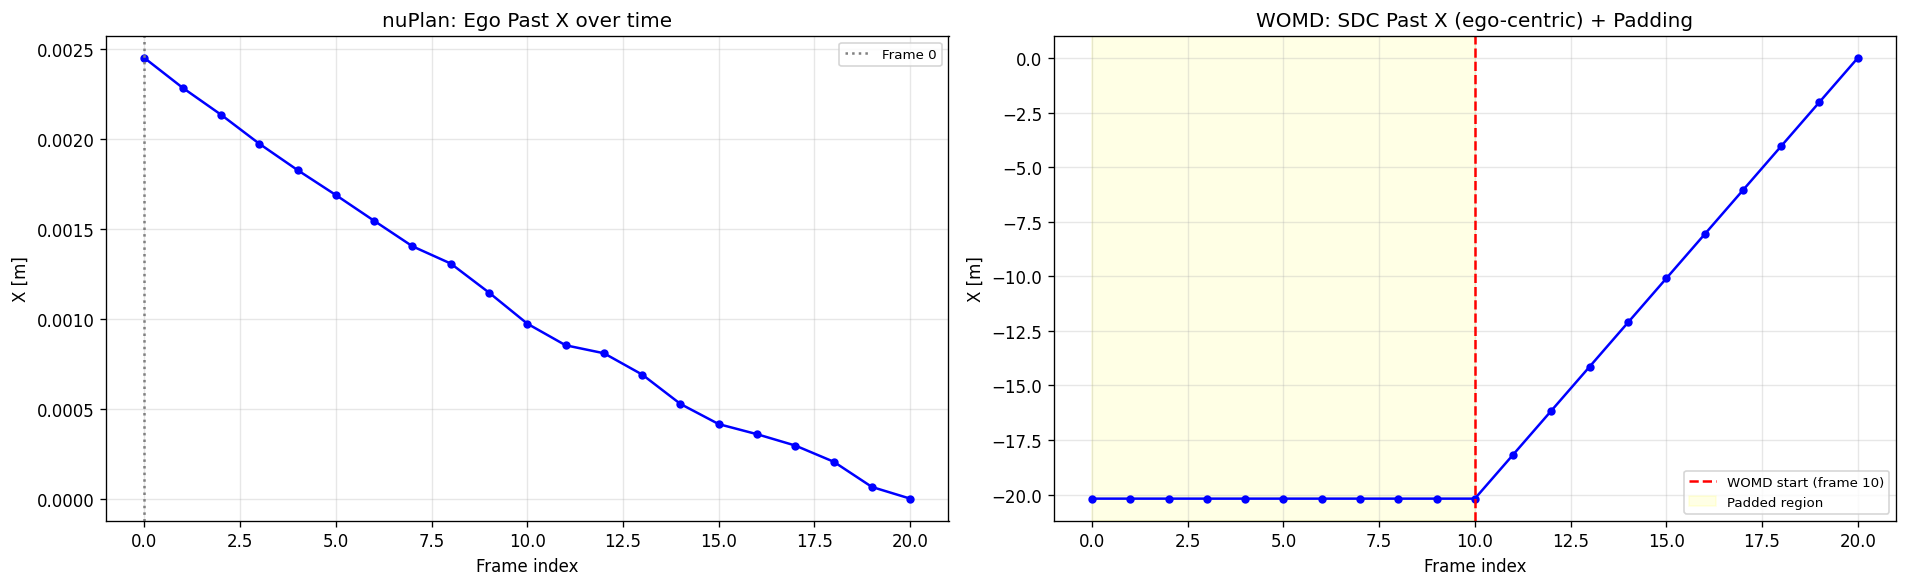

In [12]:
print("="*60)
print("HISTORY PADDING ANALYSIS")
print("="*60)

nuplan_past_frames = np_ego_past.shape[0]  # 21
womd_past_frames = ct + 1  # typically 11
padding_needed = nuplan_past_frames - womd_past_frames

print(f"\nnuPlan past frames: {nuplan_past_frames} (2.0s at 10Hz, including current)")
print(f"WOMD past frames: {womd_past_frames} (current_time_index={ct}, {ct*0.1:.1f}s including current)")
print(f"Padding needed: {padding_needed} frames")

print(f"\nPadding strategy: Repeat the EARLIEST valid state {padding_needed} times")
print(f"  This fills frames [0..{padding_needed-1}] with the state at WOMD frame 0")
print(f"  WOMD frames 0..{ct} map to output frames {padding_needed}..{nuplan_past_frames-1}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.set_title('nuPlan: Ego Past X over time')
ax.plot(range(nuplan_past_frames), np_ego_past[:, 0], 'b-o', markersize=4)
ax.axvline(x=0, color='gray', linestyle=':', label='Frame 0')
ax.set_xlabel('Frame index'); ax.set_ylabel('X [m]')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.set_title('WOMD: SDC Past X (ego-centric) + Padding')
# Build the full past array (ct+1 frames), filling invalid frames with nearest valid
sdc_past_lx_full = sdc_lx[:ct+1].copy()
# Forward-fill invalid frames with the last valid value
for t in range(1, ct+1):
    if not sdc_valid[t]:
        sdc_past_lx_full[t] = sdc_past_lx_full[t-1]
# Backward-fill if frame 0 is invalid
if not sdc_valid[0]:
    first_valid = np.argmax(sdc_valid[:ct+1])
    sdc_past_lx_full[:first_valid] = sdc_past_lx_full[first_valid]

# Pad to 21 frames by repeating the earliest frame
padded_x = np.concatenate([np.full(padding_needed, sdc_past_lx_full[0]), sdc_past_lx_full])
ax.plot(range(len(padded_x)), padded_x, 'b-o', markersize=4)
ax.axvline(x=padding_needed, color='red', linestyle='--', label=f'WOMD start (frame {padding_needed})')
ax.axvspan(0, padding_needed, alpha=0.1, color='yellow', label='Padded region')
ax.set_xlabel('Frame index'); ax.set_ylabel('X [m]')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
print(f"  SDC valid past frames: {int(sdc_valid[:ct+1].sum())}/{ct+1}")
print(f"  Padded array length: {len(padded_x)} (target: {nuplan_past_frames})")

plt.tight_layout()
plt.show()

---
## 8. Speed Limit Comparison

In [13]:
# nuPlan
np_has = np_has_speed.flatten().astype(bool)
np_sl = np_speed[np_has].flatten()

# WOMD
womd_sl_mph = [mf.lane.speed_limit_mph for mf in womd_lanes if mf.lane.speed_limit_mph > 0]
womd_sl_mps = [s * 0.44704 for s in womd_sl_mph]

print("="*60)
print("SPEED LIMIT COMPARISON")
print("="*60)
print(f"\nnuPlan (m/s):")
if len(np_sl) > 0:
    print(f"  Lanes with speed limit: {len(np_sl)}")
    print(f"  Range: [{np_sl.min():.1f}, {np_sl.max():.1f}] m/s")
    print(f"  Mean: {np_sl.mean():.1f} m/s")
else:
    print(f"  No lanes with speed limit")

print(f"\nWOMD (mph -> m/s):")
if len(womd_sl_mph) > 0:
    print(f"  Lanes with speed limit: {len(womd_sl_mph)}/{len(womd_lanes)}")
    print(f"  Range (mph): [{min(womd_sl_mph):.0f}, {max(womd_sl_mph):.0f}]")
    print(f"  Range (m/s): [{min(womd_sl_mps):.1f}, {max(womd_sl_mps):.1f}]")
    print(f"  Mean: {np.mean(womd_sl_mps):.1f} m/s")
else:
    print(f"  No lanes with speed limit")

print(f"\n  Conversion: speed_limit_mph * 0.44704 = speed_limit_m/s")

SPEED LIMIT COMPARISON

nuPlan (m/s):
  No lanes with speed limit

WOMD (mph -> m/s):
  Lanes with speed limit: 285/290
  Range (mph): [15, 45]
  Range (m/s): [6.7, 20.1]
  Mean: 13.5 m/s

  Conversion: speed_limit_mph * 0.44704 = speed_limit_m/s


---
## 9. Full Scene Side-by-Side

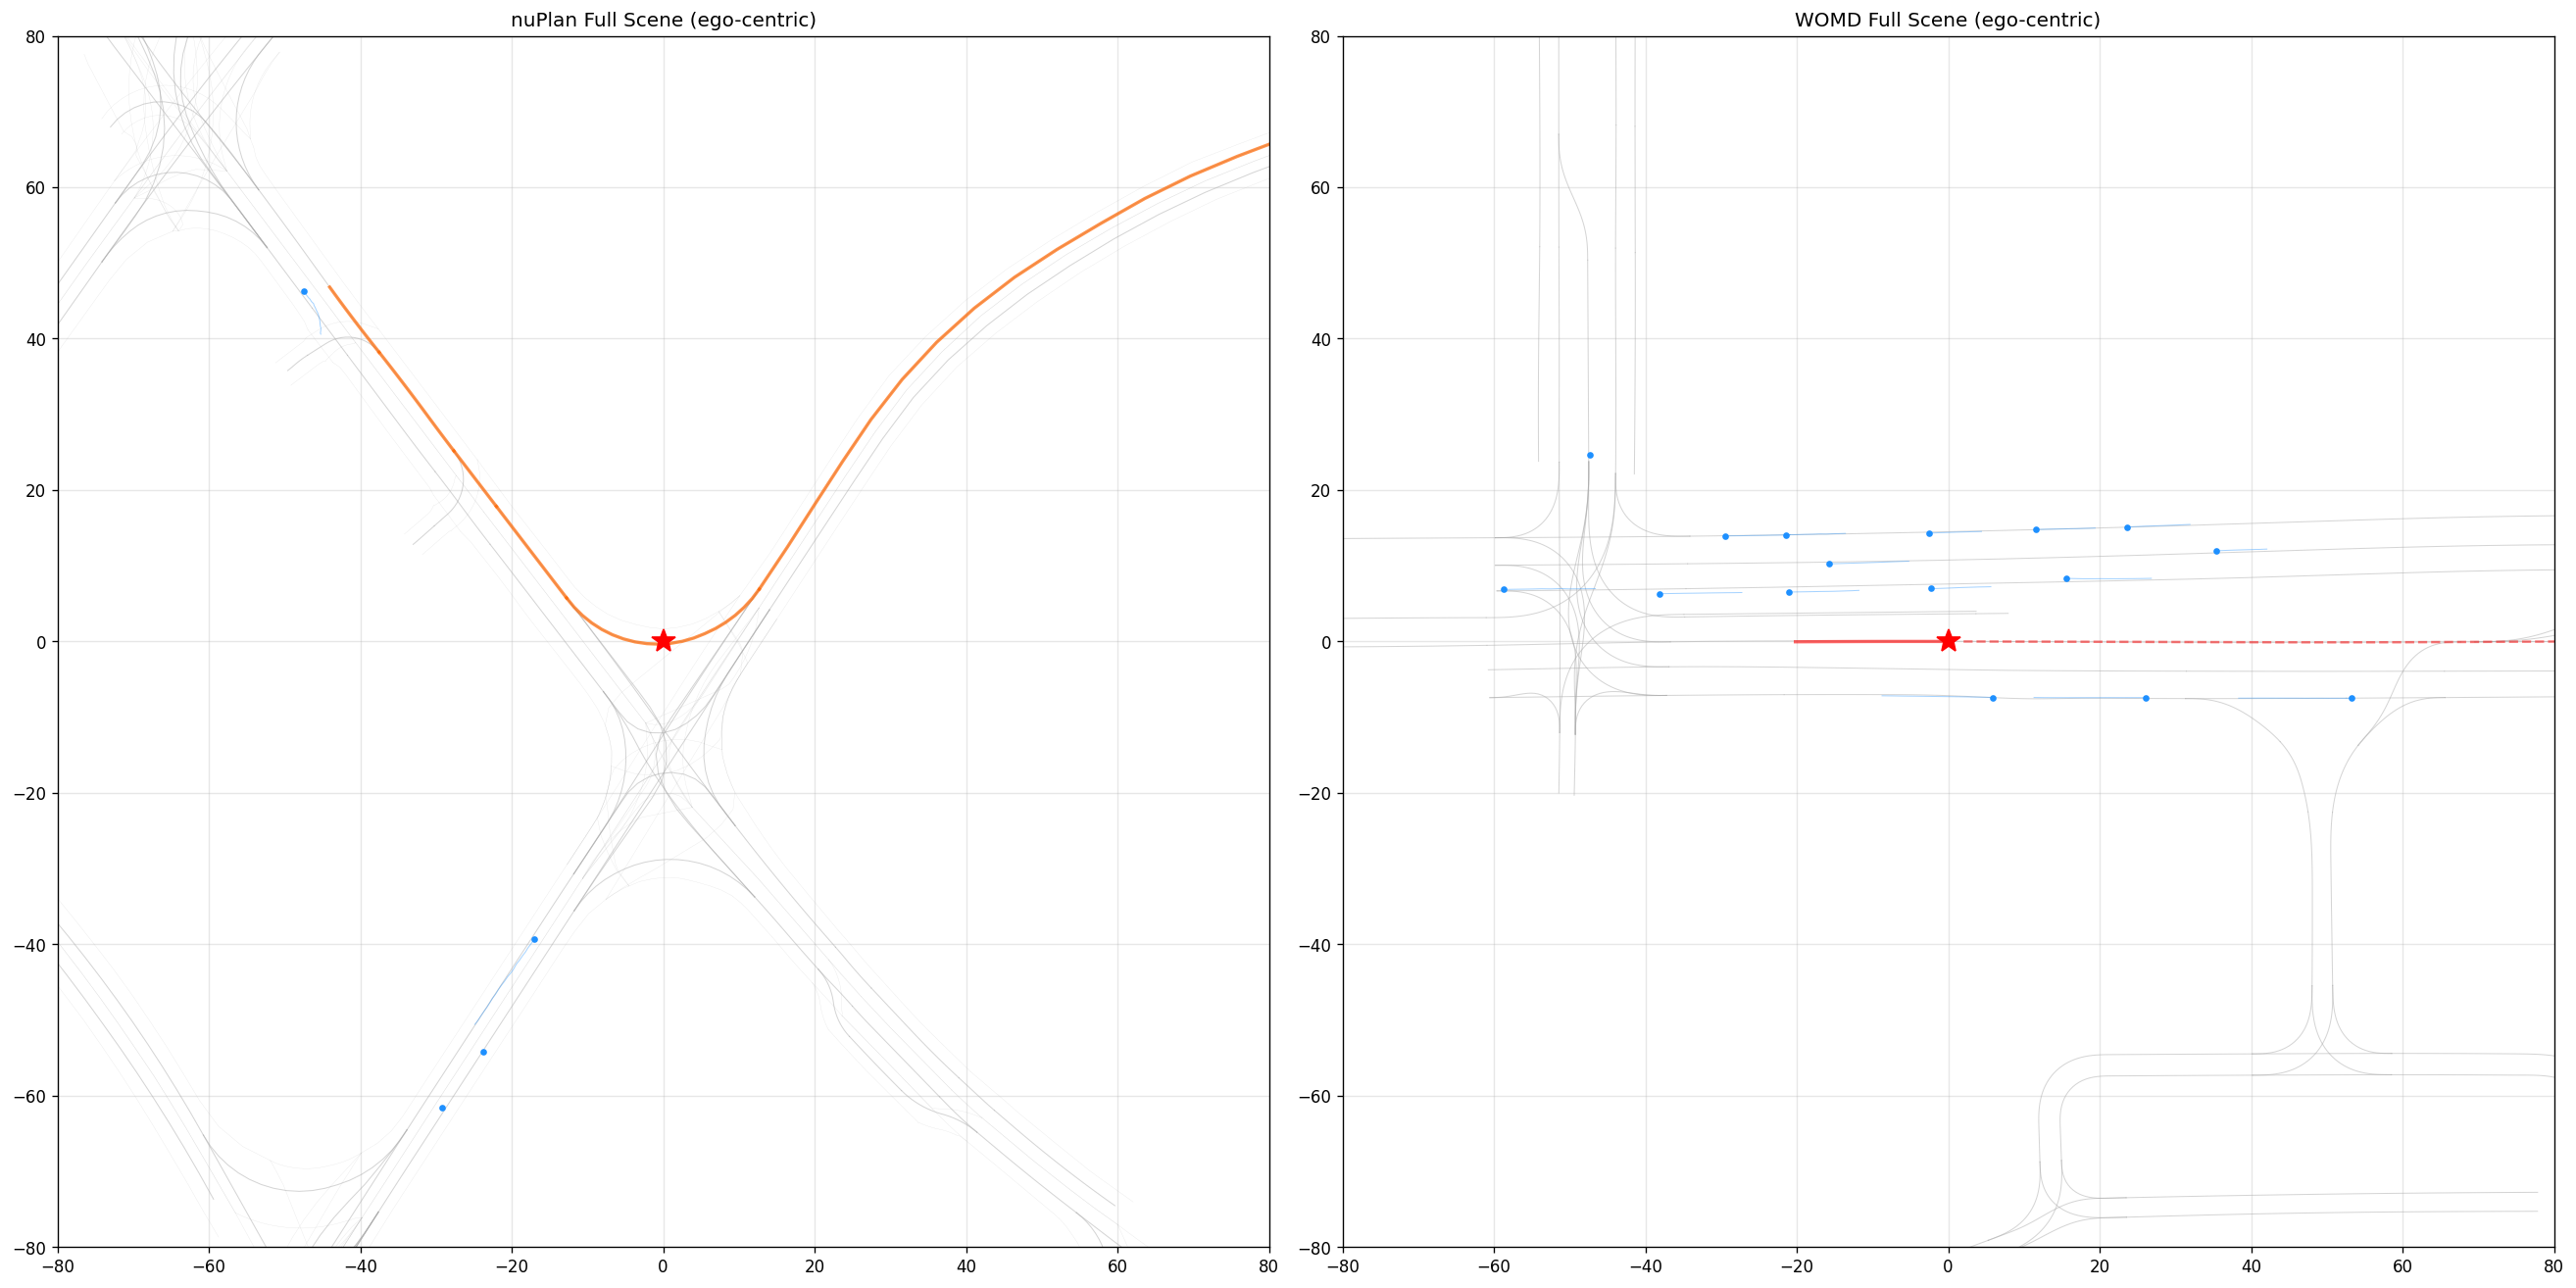

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(22, 11))

# ============ nuPlan ============
ax = axes[0]
ax.set_aspect('equal')
ax.set_title('nuPlan Full Scene (ego-centric)', fontsize=12)

# Lanes
for i in range(np_lanes.shape[0]):
    lane = np_lanes[i]
    if not np.any(np.abs(lane) > 1e-6): continue
    tl = lane[0, 8:12]
    if tl[0] > 0.5: c = '#00cc44'
    elif tl[1] > 0.5: c = '#ffcc00'
    elif tl[2] > 0.5: c = '#ff3333'
    else: c = '#aaaaaa'
    ax.plot(lane[:,0], lane[:,1], '-', color=c, linewidth=0.6, alpha=0.5)
    ax.plot(lane[:,0]+lane[:,4], lane[:,1]+lane[:,5], '-', color=c, linewidth=0.2, alpha=0.3)
    ax.plot(lane[:,0]+lane[:,6], lane[:,1]+lane[:,7], '-', color=c, linewidth=0.2, alpha=0.3)

# Route
for i in range(np_route.shape[0]):
    if np.any(np.abs(np_route[i]) > 1e-6):
        ax.plot(np_route[i,:,0], np_route[i,:,1], '-', color='#ff6600', linewidth=2, alpha=0.7)

# Neighbors
for i in range(np_nb_past.shape[0]):
    if not np.any(np.abs(np_nb_past[i,-1]) > 1e-6): continue
    t = np_nb_past[i,-1,8:11]
    if t[0] > 0.5: c = 'dodgerblue'
    elif t[1] > 0.5: c = 'orange'
    else: c = 'limegreen'
    ax.plot(np_nb_past[i,:,0], np_nb_past[i,:,1], '-', color=c, linewidth=0.6, alpha=0.4)
    ax.plot(np_nb_past[i,-1,0], np_nb_past[i,-1,1], 'o', color=c, markersize=3)

# Ego
ax.plot(np_ego_past[:,0], np_ego_past[:,1], 'r-', linewidth=2, alpha=0.6)
ax.plot(np_ego_future[:,0], np_ego_future[:,1], 'r--', linewidth=1.5, alpha=0.5)
ax.plot(0, 0, 'r*', markersize=15)
ax.set_xlim(-80, 80); ax.set_ylim(-80, 80)
ax.grid(True, alpha=0.3)

# ============ WOMD ============
ax = axes[1]
ax.set_aspect('equal')
ax.set_title('WOMD Full Scene (ego-centric)', fontsize=12)

# Lanes with TL
for mf in womd_lanes:
    pts = get_polyline(mf.lane)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) > 100: continue
    lx, ly = womd_to_ego(pts[:,0], pts[:,1])
    if mf.id in womd_tl_at_ct:
        state = womd_tl_at_ct[mf.id]
        if state == 'GO': c = '#00cc44'
        elif state == 'CAUTION': c = '#ffcc00'
        elif state == 'STOP': c = '#ff3333'
        else: c = '#999999'
    else:
        c = '#aaaaaa'
    ax.plot(lx, ly, '-', color=c, linewidth=0.6, alpha=0.5)
    # Note: boundary plotting skipped in full scene (full RoadLine polylines
    # extend far beyond individual lanes; see Cell 9 for per-lane detail)

# Agents
for i, track in enumerate(scenario.tracks):
    if i == scenario.sdc_track_index: continue
    if not track.states[ct].valid: continue
    xs = np.array([s.center_x for s in track.states])
    ys = np.array([s.center_y for s in track.states])
    valids = np.array([s.valid for s in track.states])
    lxs, lys = womd_to_ego(xs, ys)
    if np.sqrt(lxs[ct]**2 + lys[ct]**2) > 80: continue
    obj_t = {1:'dodgerblue', 2:'orange', 3:'limegreen'}.get(track.object_type, 'gray')
    pv = valids[:ct+1]
    ax.plot(lxs[:ct+1][pv], lys[:ct+1][pv], '-', color=obj_t, linewidth=0.6, alpha=0.4)
    ax.plot(lxs[ct], lys[ct], 'o', color=obj_t, markersize=3)

# SDC
ax.plot(sdc_lx[:ct+1][sdc_valid[:ct+1]], sdc_ly[:ct+1][sdc_valid[:ct+1]], 'r-', linewidth=2, alpha=0.6)
ax.plot(sdc_lx[ct+1:][sdc_valid[ct+1:]], sdc_ly[ct+1:][sdc_valid[ct+1:]], 'r--', linewidth=1.5, alpha=0.5)
ax.plot(0, 0, 'r*', markersize=15)
ax.set_xlim(-80, 80); ax.set_ylim(-80, 80)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 10. Final Sign-Off Checklist

Review all verification items below. Set each to `True` once confirmed.

In [15]:
# ============================================================
# PHASE 0 SIGN-OFF CHECKLIST
# Set each to True once visually confirmed
# ============================================================

checklist = {
    "1. Ego trajectory in ego-centric frame (origin at current ego)": False,
    "2. Heading stored as (cos_h, sin_h) in past, radians in future": False,
    "3. Past: 21 frames (2.0s), need padding 10 frames for WOMD": False,
    "4. Future: 80 frames (8.0s), direct match": False,
    "5. Neighbor agents sorted by distance, max 32, max 10 ped+bike": False,
    "6. Agent past 11-dim: [x,y,cos_h,sin_h,vx,vy,w,l,type(3)]": False,
    "7. Agent future 3-dim: [x,y,heading] in ego-centric": False,
    "8. Lane 12-dim: [cx,cy,dx,dy,left_off(2),right_off(2),tl(4)]": False,
    "9. Boundary offsets = boundary_point - center_point": False,
    "10. Direction vectors = point[i+1] - point[i]": False,
    "11. TL mapping: GO->green, CAUTION->yellow, STOP->red": False,
    "12. Route lanes synthesis via SDC future projection": False,
    "13. Static objects: stop_sign -> generic, zero-pad rest": False,
    "14. Speed limit: WOMD mph * 0.44704 -> m/s": False,
    "15. Acceleration: velocity finite difference": False,
    "16. Steering/yaw_rate: heading finite difference": False,
    "17. CYCLIST -> BICYCLE mapping, ignore OTHER": False,
}

print("=" * 70)
print("PHASE 0 SIGN-OFF CHECKLIST")
print("=" * 70)
passed = 0
for item, status in checklist.items():
    mark = 'PASS' if status else 'TODO'
    print(f"  [{mark}] {item}")
    if status: passed += 1

print(f"\n{'='*70}")
print(f"Progress: {passed}/{len(checklist)} items confirmed")
if passed == len(checklist):
    print("ALL CHECKS PASSED - Ready to proceed to Phase 1!")
else:
    print(f"{len(checklist) - passed} items remaining. Set each to True after visual confirmation.")
print(f"{'='*70}")

PHASE 0 SIGN-OFF CHECKLIST
  [TODO] 1. Ego trajectory in ego-centric frame (origin at current ego)
  [TODO] 2. Heading stored as (cos_h, sin_h) in past, radians in future
  [TODO] 3. Past: 21 frames (2.0s), need padding 10 frames for WOMD
  [TODO] 4. Future: 80 frames (8.0s), direct match
  [TODO] 5. Neighbor agents sorted by distance, max 32, max 10 ped+bike
  [TODO] 6. Agent past 11-dim: [x,y,cos_h,sin_h,vx,vy,w,l,type(3)]
  [TODO] 7. Agent future 3-dim: [x,y,heading] in ego-centric
  [TODO] 8. Lane 12-dim: [cx,cy,dx,dy,left_off(2),right_off(2),tl(4)]
  [TODO] 9. Boundary offsets = boundary_point - center_point
  [TODO] 10. Direction vectors = point[i+1] - point[i]
  [TODO] 11. TL mapping: GO->green, CAUTION->yellow, STOP->red
  [TODO] 12. Route lanes synthesis via SDC future projection
  [TODO] 13. Static objects: stop_sign -> generic, zero-pad rest
  [TODO] 14. Speed limit: WOMD mph * 0.44704 -> m/s
  [TODO] 15. Acceleration: velocity finite difference
  [TODO] 16. Steering/yaw_rat

---
## Appendix: Detailed Field Mapping Reference

This table summarizes the exact conversion logic for Phase 1 implementation.

### ego_agent_past (21, 14)

| Dim | nuPlan | WOMD Source | Conversion |
|-----|--------|-------------|------------|
| 0 | x | `track.states[t].center_x` | Transform to ego-centric |
| 1 | y | `track.states[t].center_y` | Transform to ego-centric |
| 2 | cos_h | `track.states[t].heading` | `cos(heading - ego_heading)` |
| 3 | sin_h | `track.states[t].heading` | `sin(heading - ego_heading)` |
| 4 | vx | `track.states[t].velocity_x` | Rotate to ego frame |
| 5 | vy | `track.states[t].velocity_y` | Rotate to ego frame |
| 6 | ax | N/A | `(vx[t] - vx[t-1]) / 0.1` |
| 7 | ay | N/A | `(vy[t] - vy[t-1]) / 0.1` |
| 8 | width | `track.states[t].width` | Direct |
| 9 | length | `track.states[t].length` | Direct |
| 10 | ego_type | Always 1 | Set to 1 |
| 11-13 | zeros | N/A | Set to 0 |

### ego_current_state (16,)

| Dim | Field | Source |
|-----|-------|--------|
| 0-1 | x, y | Same as past dim 0-1 |
| 2-3 | cos_h, sin_h | Same as past dim 2-3 |
| 4-7 | vx, vy, ax, ay | Same as past dim 4-7 |
| 8 | steering_angle | `arctan(yaw_rate * wheelbase / |v|)` |
| 9 | yaw_rate | `(heading[t] - heading[t-1]) / dt` |
| 10-11 | width, length | Direct |
| 12 | ego_type | 1 |
| 13-15 | zeros | 0 |

### lanes (70, 20, 12)

| Dim | Field | WOMD Source |
|-----|-------|-------------|
| 0-1 | center_x, center_y | `lane.polyline[i].x/y` (interpolated to 20 pts) |
| 2-3 | dx, dy | `center[i+1] - center[i]` |
| 4-5 | left_offset_x/y | `left_boundary[i] - center[i]` (interpolated) |
| 6-7 | right_offset_x/y | `right_boundary[i] - center[i]` (interpolated) |
| 8-11 | tl one-hot | Mapped from `dynamic_map_states` |